# LayingRate_Model.ipynb
**ICS 3202 — Artificial Intelligence | Project Deliverable 2**

**Goal:** forecast a laying flock's **laying rate** (% of hens laying per day) **1, 4 and 8 weeks ahead** from its weekly records,
so that the poultry ERP can warn a farmer early when a flock is heading below the breed standard.

**Data:** 9 Lohmann Brown flocks × 52 weeks of real farm records, Colombia 2003–2015
([Cabezas-García et al., 2024, Mendeley Data, CC BY 4.0](https://data.mendeley.com/datasets/t2gzbht99m)). See `Lohmann_Exploration.ipynb`.

**What this notebook shows**
1. The data is reshaped into what a farm records each week, and the model's inputs are built only from the past.
2. Models are scored on **flocks they never saw**, and a random split is shown to flatter them.
3. Three models are compared with **three simple rules a farmer could use**. A model is only worth having if it beats them.
4. Evidence that the model learned: its error falls as it sees more flocks, and it uses several inputs, not one.
5. The chosen models are saved in the format the `FlockAgent` and API load.

Runs top to bottom in Colab (about 3 minutes) or locally from the repo folder.

## 1. Load the data and keep only what a farm records

In [1]:
import io, os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LOCAL_COPY = 'data/lohmann_brown_flocks.txt'
URL = ('https://data.mendeley.com/public-files/datasets/t2gzbht99m/files/'
       '5dfb5617-19d0-4307-b969-3ac722b1c12b/file_downloaded')
if os.path.exists(LOCAL_COPY):
    raw = pd.read_csv(LOCAL_COPY, sep='\t')
else:
    request = urllib.request.Request(URL, headers={'User-Agent': 'Mozilla/5.0'})
    raw = pd.read_csv(io.BytesIO(urllib.request.urlopen(request).read()), sep='\t')
raw = raw.dropna(how='all').reset_index(drop=True)   # the file ends with a blank line
raw['flock_id'] = 'G' + raw['Generation'].astype(int).astype(str) + '-F' + raw['Flock'].astype(int).astype(str)
print(raw.shape, '-', raw['flock_id'].nunique(), 'flocks')

(468, 23) - 9 flocks


In [2]:
# One list of weekly records per flock, with only the five things a farm writes
# down. Laying rate, eggs per hen, feed conversion etc. are arithmetic on these
# (shown in the exploration notebook), so they are recalculated, never read.
flocks = {}
for flock_id, rows in raw.sort_values('WeekOld').groupby('flock_id'):
    previous = int(rows['HousedHens'].iloc[0])
    weeks = []
    for r in rows.itertuples():
        hens = int(r.BirdsBalance)
        weeks.append({'age_weeks': int(r.WeekOld), 'hens': hens, 'eggs': int(r.NumberEggsPerWeek),
                      'feed_kg': float(r.FeedPerWeek), 'deaths': previous - hens})
        previous = hens
    flocks[flock_id] = weeks

# The breed's target curve: the latest guide (generation 3), used for every flock
latest = raw[raw['Generation'] == 3]
curve = (pd.to_numeric(latest['IdealLayingRateDay'], errors='coerce')
           .groupby(latest['WeekOld'].astype(int)).median().dropna().round(2).to_dict())
print('Breed standard covers weeks', min(curve), 'to', max(curve))
pd.DataFrame(flocks['G2-F2']).head()

Breed standard covers weeks 19 to 70


,age_weeks,hens,eggs,feed_kg,deaths
0,19,1548,8,976.79,0
1,20,1547,35,1083.40,1
2,21,1546,204,1174.40,1
3,22,1546,828,1174.19,0
4,23,1546,2635,1222.89,0


## 2. Inputs and target

For every week of every flock, the model gets what is known **at the end of that week** and has to predict the laying rate
`h` weeks later. It never sees the future.

| Input | Meaning |
|---|---|
| `age_weeks` | the flock's age this week |
| `lay_rate`, `lay_rate_1`, `lay_rate_2` | laying rate this week and the two weeks before (%) |
| `trend` | change over those two weeks (points) |
| `feed_g`, `feed_g_1` | feed per hen per day this week and last week (g) |
| `mortality_pct`, `cum_mortality_pct` | deaths + culls this week, and since housing (%) |
| `standard`, `gap` | the breed standard this week, and how far the flock is above or below it |
| `target_age_weeks`, `target_standard` | the age being forecast, and the breed standard then |

The same code builds these for training and for live forecasts (`ml_engine/data.py`).

In [3]:
HORIZONS = (1, 4, 8)
FEATURES = ['age_weeks', 'lay_rate', 'lay_rate_1', 'lay_rate_2', 'trend', 'feed_g', 'feed_g_1',
            'mortality_pct', 'cum_mortality_pct', 'standard', 'gap', 'target_age_weeks', 'target_standard']

def derive(weeks):
    f = pd.DataFrame(weeks)
    days = 7 * f['hens']
    f['lay_rate'] = 100 * f['eggs'] / days
    f['feed_g'] = 1000 * f['feed_kg'] / days
    f['mortality_pct'] = 100 * f['deaths'] / (f['hens'] + f['deaths'])
    f['cum_mortality_pct'] = 100 * f['deaths'].cumsum() / (f['hens'].iloc[0] + f['deaths'].iloc[0])
    f['standard'] = f['age_weeks'].map(curve)
    f['gap'] = f['lay_rate'] - f['standard']
    f['lay_rate_1'] = f['lay_rate'].shift(1)
    f['lay_rate_2'] = f['lay_rate'].shift(2)
    f['trend'] = f['lay_rate'] - f['lay_rate_2']
    f['feed_g_1'] = f['feed_g'].shift(1)
    return f

def training_table(horizon):
    parts = []
    for flock_id, weeks in flocks.items():
        f = derive(weeks)
        f['target_age_weeks'] = f['age_weeks'] + horizon
        f['target_standard'] = f['target_age_weeks'].map(curve)
        f['target'] = f['lay_rate'].shift(-horizon)      # the laying rate h weeks later
        f['flock_id'] = flock_id
        parts.append(f)
    return pd.concat(parts, ignore_index=True).dropna(subset=FEATURES + ['target']).reset_index(drop=True)

tables = {h: training_table(h) for h in HORIZONS}
for h, t in tables.items():
    print(f'{h} week(s) ahead: {len(t)} forecasts to learn from')
tables[4][['flock_id'] + FEATURES[:5] + ['target_age_weeks', 'target']].head()

1 week(s) ahead: 439 forecasts to learn from
4 week(s) ahead: 412 forecasts to learn from
8 week(s) ahead: 376 forecasts to learn from


,flock_id,age_weeks,lay_rate,lay_rate_1,lay_rate_2,trend,target_age_weeks,target
0,G1-F1,22,1.365818,0.156884,0.036914,1.328904,26,57.780447
1,G1-F1,23,5.592470,1.365818,0.156884,5.435585,27,69.996304
2,G1-F1,24,17.201920,5.592470,1.365818,15.836102,28,83.236246
3,G1-F1,25,35.571152,17.201920,5.592470,29.978682,29,88.164586
4,G1-F1,26,57.780447,35.571152,17.201920,40.578528,30,87.924179


## 3. How to score it fairly: leave one flock out

Weeks of the same flock are very alike. If the rows were split at random, the model would be tested on weeks sitting right next to
weeks it trained on, and it would look better than it really is. A farm using the ERP has a **new** flock. So every score below comes
from training on 8 flocks and testing on the 9th, repeated for each flock.

The next cell shows how much a random split would flatter the model.

In [4]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def forest(n=400):
    return RandomForestRegressor(n_estimators=n, min_samples_leaf=3, random_state=42, n_jobs=-1)

t = tables[4]
random_split = cross_val_predict(forest(), t[FEATURES], t['target'], cv=KFold(5, shuffle=True, random_state=0))
by_flock = cross_val_predict(forest(), t[FEATURES], t['target'], cv=LeaveOneGroupOut(), groups=t['flock_id'])
print(f"4 weeks ahead, random forest - random 5-fold split:  MAE {mean_absolute_error(t['target'], random_split):.2f} points")
print(f"4 weeks ahead, random forest - leave one flock out:  MAE {mean_absolute_error(t['target'], by_flock):.2f} points")

4 weeks ahead, random forest - random 5-fold split:  MAE 2.62 points
4 weeks ahead, random forest - leave one flock out:  MAE 2.83 points


The random split reports a smaller error than the honest one. That gap is the model recognising flocks it has already seen.
Everything from here on uses leave-one-flock-out.

## 4. Models against simple rules

**Baselines**, rules a farmer could use with no model at all:
- *Same as this week*: assume the rate stays where it is.
- *Breed standard*: assume the flock follows the breed guide.
- *Standard + this week's gap*: the guide, shifted by how far off the flock is now.

**Models:** ridge regression (linear), random forest and gradient boosting (both tree ensembles).

In [5]:
CANDIDATES = {
    'Ridge regression': lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'Random forest': lambda: forest(),
    'Gradient boosting': lambda: GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42),
}
BASELINES = {
    'Same as this week': lambda t: t['lay_rate'],
    'Breed standard': lambda t: t['target_standard'],
    "Standard + this week's gap": lambda t: t['target_standard'] + t['gap'],
}

def score(y, p):
    err = np.abs(np.asarray(y) - np.asarray(p))
    return {'mae': float(err.mean()), 'r2': float(r2_score(y, p)), 'p80_error': float(np.quantile(err, 0.8))}

results, held_out = {}, {}
for h, t in tables.items():
    results[h] = {name: score(t['target'], rule(t)) for name, rule in BASELINES.items()}
    for name, make in CANDIDATES.items():
        p = cross_val_predict(make(), t[FEATURES], t['target'], cv=LeaveOneGroupOut(), groups=t['flock_id'])
        held_out[(h, name)] = p
        results[h][name] = score(t['target'], p)

mae = pd.DataFrame({f'{h} wk ahead': {m: r['mae'] for m, r in res.items()} for h, res in results.items()})
r2 = pd.DataFrame({f'{h} wk ahead': {m: r['r2'] for m, r in res.items()} for h, res in results.items()})
print('Mean absolute error on unseen flocks (laying-rate points, lower is better)')
display(mae.sort_values('1 wk ahead').round(2))
print('R² on unseen flocks (higher is better)')
display(r2.loc[mae.sort_values('1 wk ahead').index].round(2))

Mean absolute error on unseen flocks (laying-rate points, lower is better)


,1 wk ahead,4 wk ahead,8 wk ahead
Gradient boosting,2.47,3.05,3.06
Random forest,2.50,2.83,2.91
Ridge regression,2.57,3.31,3.29
Standard + this week's gap,3.06,5.73,6.66
Same as this week,3.50,6.89,8.38
Breed standard,5.36,3.44,3.14


R² on unseen flocks (higher is better)


,1 wk ahead,4 wk ahead,8 wk ahead
Gradient boosting,0.92,0.50,0.48
Random forest,0.91,0.57,0.53
Ridge regression,0.90,0.44,0.43
Standard + this week's gap,0.83,-3.04,-5.70
Same as this week,0.74,-5.29,-9.41
Breed standard,0.07,0.26,0.41


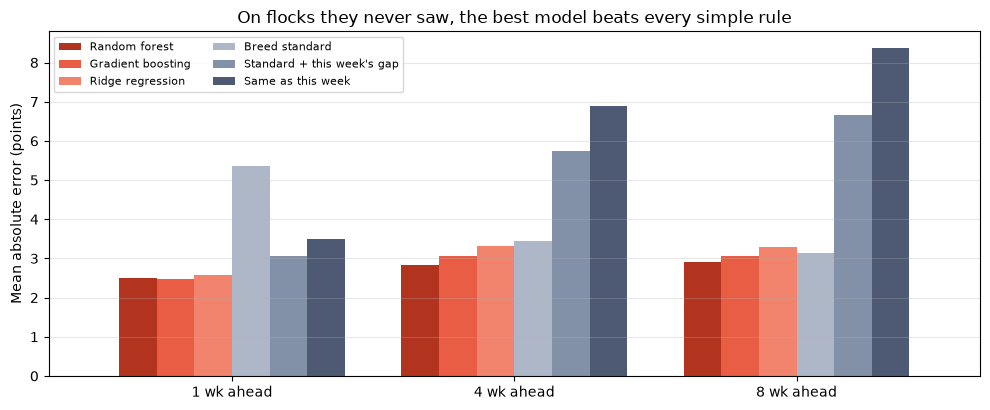

In [6]:
order = mae.sort_values('4 wk ahead').index
ax = mae.loc[order].T.plot.bar(figsize=(10, 4.2), width=0.8, rot=0,
                                color=['#b2341e', '#e85d43', '#f2846d', '#aeb7c8', '#8290a8', '#4e5a74'])
ax.set_ylabel('Mean absolute error (points)')
ax.set_title('On flocks they never saw, the best model beats every simple rule')
ax.legend(fontsize=8, ncol=2); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

In [7]:
chosen = {h: min(CANDIDATES, key=lambda m: results[h][m]['mae']) for h in HORIZONS}
for h in HORIZONS:
    best_rule = min(BASELINES, key=lambda m: results[h][m]['mae'])
    m, b = results[h][chosen[h]]['mae'], results[h][best_rule]['mae']
    print(f"{h} wk: {chosen[h]:17s} MAE {m:.2f}  vs best rule ({best_rule}) {b:.2f}  -> {100 * (b - m) / b:.0f}% smaller error")

1 wk: Gradient boosting MAE 2.47  vs best rule (Standard + this week's gap) 3.06  -> 19% smaller error
4 wk: Random forest     MAE 2.83  vs best rule (Breed standard) 3.44  -> 18% smaller error
8 wk: Random forest     MAE 2.91  vs best rule (Breed standard) 3.14  -> 8% smaller error


**Reading the results**
- **1 week ahead,** every model beats every rule. The best rule, the standard shifted by this week's gap, is off by about 3 points.
  The models are off by about 2.5.
- **4 weeks ahead,** "same as this week" falls apart, because flocks move a lot in a month, especially at the start of lay.
  The breed standard is the best rule here, and the random forest is clearly better than it.
- **8 weeks ahead,** the margin over the breed standard is small. Two months out, recent weeks say little, so the forecast leans on
  the breed curve. That is honest behaviour, and the app labels these forecasts accordingly.
- **The tree models win at 4 and 8 weeks.** Their advantage is in combining age, recent trend and the gap to the standard non-linearly.
  Ridge, being linear, cannot do that.

## 5. Where the errors come from

In [8]:
rows = []
for h in HORIZONS:
    t = tables[h]
    err = np.abs(t['target'] - held_out[(h, chosen[h])])
    std_err = np.abs(t['target'] - t['target_standard'])
    onset = t['target_age_weeks'] <= 28
    rows.append({'horizon': f'{h} wk', 'model MAE, start of lay (to week 28)': err[onset].mean(),
                 'model MAE, after the peak': err[~onset].mean(),
                 'breed standard MAE, after the peak': std_err[~onset].mean()})
pd.DataFrame(rows).set_index('horizon').round(2)

,"model MAE, start of lay (to week 28)","model MAE, after the peak","breed standard MAE, after the peak"
horizon,,,
1 wk,4.07,2.22,3.15
4 wk,5.02,2.63,3.15
8 wk,NaN,2.91,3.14


In [9]:
per_flock = pd.DataFrame({h: (np.abs(tables[h]['target'] - held_out[(h, chosen[h])])
                              .groupby(tables[h]['flock_id']).mean()) for h in HORIZONS})
per_flock.columns = [f'{h} wk ahead' for h in HORIZONS]
per_flock.round(2)

,1 wk ahead,4 wk ahead,8 wk ahead
flock_id,,,
G1-F1,2.58,3.09,2.54
G1-F2,2.22,3.05,2.78
G1-F3,2.07,2.47,2.31
G2-F1,2.08,2.13,2.15
G2-F2,3.99,4.34,4.63
G2-F3,2.18,2.31,2.56
G3-F1,2.13,2.33,2.62
G3-F2,2.58,3.45,3.75
G3-F3,2.43,2.25,2.79


- **The start of lay is the hardest part.** Flocks begin laying at different times, and the rate climbs by 10–20 points a week.
  After the peak, errors are much smaller, and the models beat the breed standard there too. The 8-week row has no start-of-lay
  forecasts, because the earliest forecast (made at week 21) lands on week 29.
- **Errors vary by flock.** The flocks with sudden unexplained dips are hardest. Those dips come from things the records don't
  capture, such as disease, heat or a feed change.

## 6. Did the model really learn? Two checks

**Check 1 — learning curve.** If the model is learning patterns that carry across flocks, its error on an unseen flock should fall
as it is trained on more flocks. A model that only memorises would not improve this way.

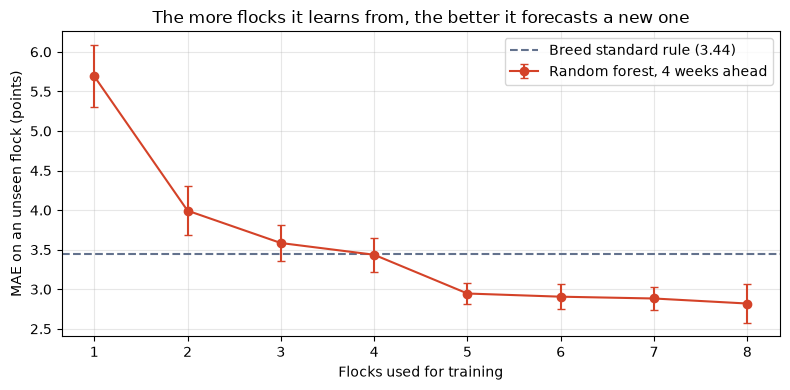

k,1,2,3,4,5,6,7,8
mean,5.69,3.99,3.58,3.44,2.95,2.91,2.88,2.82
sem,0.39,0.31,0.22,0.21,0.13,0.16,0.14,0.24


In [10]:
rng = np.random.default_rng(0)
t = tables[4]
ids = sorted(t['flock_id'].unique())
curve_rows = []
for test_flock in ids:
    others = [f for f in ids if f != test_flock]
    test = t[t['flock_id'] == test_flock]
    for k in range(1, len(others) + 1):
        for _ in range(3 if k < len(others) else 1):
            pick = rng.choice(others, size=k, replace=False)
            train = t[t['flock_id'].isin(pick)]
            p = forest(200).fit(train[FEATURES], train['target']).predict(test[FEATURES])
            curve_rows.append({'k': k, 'mae': mean_absolute_error(test['target'], p)})
lc = pd.DataFrame(curve_rows).groupby('k')['mae'].agg(['mean', 'sem'])
std_only = np.abs(t['target'] - t['target_standard']).mean()

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(lc.index, lc['mean'], yerr=lc['sem'], marker='o', color='#d44228', capsize=3, label='Random forest, 4 weeks ahead')
ax.axhline(std_only, color='#63728d', linestyle='--', label=f'Breed standard rule ({std_only:.2f})')
ax.set_xlabel('Flocks used for training'); ax.set_ylabel('MAE on an unseen flock (points)')
ax.set_title('The more flocks it learns from, the better it forecasts a new one')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()
lc.round(2).T

Trained on one flock, the forecaster is far worse than simply following the breed guide. It needs about **5 flocks** before
it beats the guide, and it keeps improving slowly after that. A model that only memorised would not get better at
forecasting a flock it has never seen.

**Check 2 — what the model relies on.** Permutation importance shuffles an input on the held-out flock and measures how much
worse the forecasts get. It uses the random forest at every horizon, so the horizons compare like for like. Age, the breed standard now and the breed standard at the target week all describe the same thing,
where the flock is on its laying curve. Shuffled one at a time, each looks unimportant because the others cover for it. So related
inputs are shuffled **together, as groups**.

If one input did all the work, as `Age` did in the old dataset, one group would dominate at every horizon.

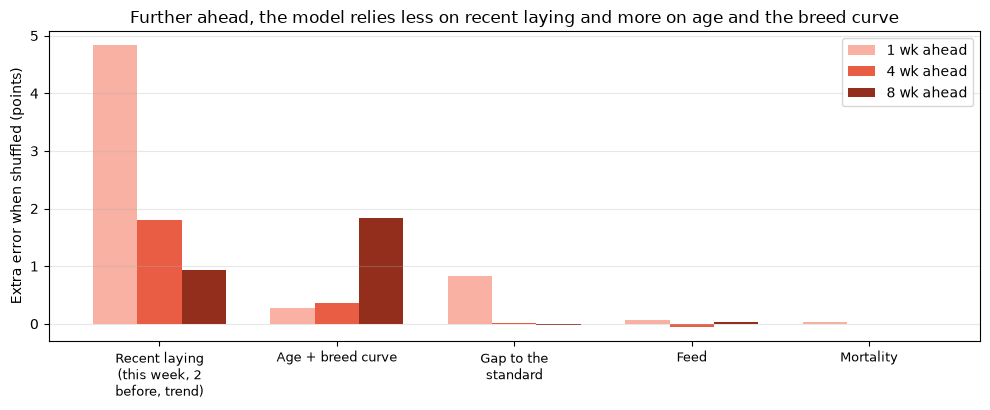

,1 wk ahead,4 wk ahead,8 wk ahead
"Recent laying (this week, 2 before, trend)",4.83,1.81,0.94
Age + breed curve,0.27,0.36,1.84
Gap to the standard,0.83,0.02,-0.03
Feed,0.06,-0.05,0.03
Mortality,0.03,-0.00,-0.01


In [11]:
GROUPS = {
    'Recent laying (this week, 2 before, trend)': ['lay_rate', 'lay_rate_1', 'lay_rate_2', 'trend'],
    'Age + breed curve': ['age_weeks', 'standard', 'target_age_weeks', 'target_standard'],
    'Gap to the standard': ['gap'],
    'Feed': ['feed_g', 'feed_g_1'],
    'Mortality': ['mortality_pct', 'cum_mortality_pct'],
}
import textwrap
rng = np.random.default_rng(0)
group_imp = {}
for h in HORIZONS:
    t = tables[h]
    extra = {g: [] for g in GROUPS}
    for test_flock in sorted(t['flock_id'].unique()):
        train, test = t[t['flock_id'] != test_flock], t[t['flock_id'] == test_flock]
        fitted = forest(200).fit(train[FEATURES], train['target'])
        base = mean_absolute_error(test['target'], fitted.predict(test[FEATURES]))
        for g, cols in GROUPS.items():
            for _ in range(5):
                X = test[FEATURES].copy()
                X[cols] = X[cols].to_numpy()[rng.permutation(len(X))]   # shuffle the group's rows together
                extra[g].append(mean_absolute_error(test['target'], fitted.predict(X)) - base)
    group_imp[f'{h} wk ahead'] = {g: float(np.mean(v)) for g, v in extra.items()}
group_imp = pd.DataFrame(group_imp)

ax = group_imp.plot.bar(figsize=(10, 4.2), rot=0, width=0.75, color=['#f8b1a2', '#e85d43', '#932e1c'])
ax.set_ylabel('Extra error when shuffled (points)')
ax.set_title('Further ahead, the model relies less on recent laying and more on age and the breed curve')
ax.set_xticklabels([textwrap.fill(g, 18) for g in group_imp.index], fontsize=9)
ax.grid(axis='y', alpha=0.3); plt.tight_layout(); plt.show()
group_imp.round(2)

This is the clearest sign that the model learned something real:
- **For next week,** it leans almost entirely on the flock's **recent laying**. Flocks change slowly from week to week.
- **For two months out,** it shifts weight to **age and the breed curve**. Recent weeks say little about week 8, but where the
  flock is on its laying curve says a lot.

Nobody told it to do this. It worked out from the data how much to trust each kind of evidence at each horizon.
**Feed and mortality** barely matter here, because feed per hen hardly varied on this farm. On a farm where feed varies more, it could matter.

## 7. One unseen flock, forecast week by week

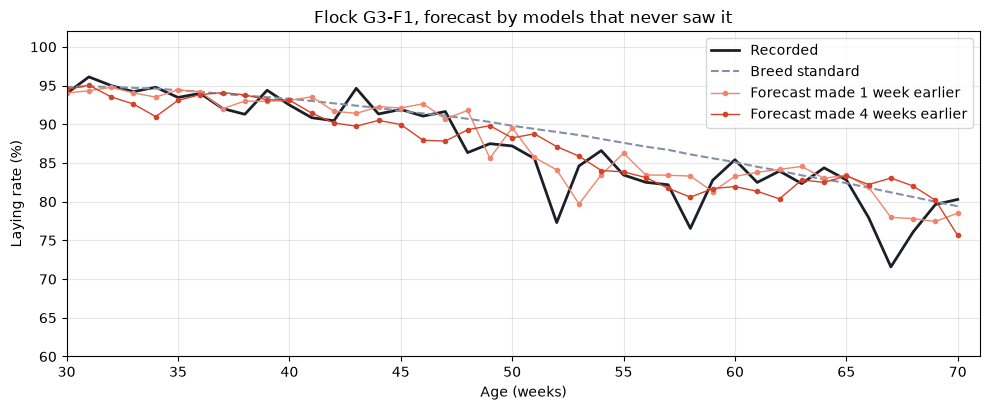

In [12]:
flock = 'G3-F1'
fig, ax = plt.subplots(figsize=(10, 4.2))
actual = derive(flocks[flock])
ax.plot(actual['age_weeks'], actual['lay_rate'], color='#1b1f28', linewidth=2, label='Recorded')
ax.plot(list(curve), list(curve.values()), color='#8290a8', linestyle='--', label='Breed standard')
for h, colour in ((1, '#f2846d'), (4, '#d44228')):
    t = tables[h]
    mask = (t['flock_id'] == flock).to_numpy()
    ax.plot(t.loc[mask, 'target_age_weeks'], held_out[(h, chosen[h])][mask], marker='.', color=colour,
            linewidth=1, label=f'Forecast made {h} week{"s" if h > 1 else ""} earlier')
ax.set_xlim(30, 71); ax.set_ylim(60, 102)
ax.set_xlabel('Age (weeks)'); ax.set_ylabel('Laying rate (%)')
ax.set_title(f'Flock {flock}, forecast by models that never saw it')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

The forecasts follow the flock's own path rather than the breed curve. They track its slow decline, and after a sudden dip they
expect a partial recovery, as real flocks usually show. They don't predict the dips themselves. Nothing in the weekly records
signals one in advance.

## 8. Save the chosen models

In [13]:
import joblib, sklearn

bundle = {'horizons': {}, 'standard_curve': {int(k): float(v) for k, v in curve.items()}, 'features': FEATURES,
          'n_flocks': len(flocks), 'n_weeks': sum(len(w) for w in flocks.values()),
          'sklearn_version': sklearn.__version__}
for h in HORIZONS:
    t = tables[h]
    # The held-out scores estimate quality on a new flock; the saved model is
    # refitted on all 9 flocks, since there are too few to hold any back.
    fitted = CANDIDATES[chosen[h]]().fit(t[FEATURES], t['target'])
    bundle['horizons'][h] = {'model': fitted, 'model_name': chosen[h], 'results': results[h], 'n_rows': len(t)}

os.makedirs('models', exist_ok=True)
joblib.dump(bundle, 'models/flock_forecaster.joblib')
print('Saved models/flock_forecaster.joblib -', {h: chosen[h] for h in HORIZONS})

Saved models/flock_forecaster.joblib - {1: 'Gradient boosting', 4: 'Random forest', 8: 'Random forest'}


This is the same file `python -m ml_engine.train` produces, so the `FlockAgent` and the API load it directly.

## 9. Limitations — what these results do and don't show
- **One farm, one breed, one country.** Nine flocks from a farm at 2,500 m altitude in Colombia. Kenyan flocks, other breeds,
  or deep-litter housing may behave differently. The engine should be retrained on local records before anyone relies on it.
- **Nine flocks is few.** Each score is the average over 9 held-out flocks, and the per-flock table shows how much they vary.
  The learning curve is still edging down at 8 flocks, so more flocks would probably help a little.
- **The records can't explain sudden dips.** Disease, heat stress or a feed change aren't in the data, so the model forecasts the
  usual path and the agent's rules catch dips once they happen.
- **Scores on the training flocks are optimistic.** The web app's sample flock was in the training data, so the app labels its
  forecasts as better than they would be for a new flock.

## 10. How the ERP uses the model — the `FlockAgent`

`ml_engine/agent.py` wraps the forecasters in a **model-based reflex agent** (Russell & Norvig): the forecasters are its model
of how the flock will develop, and condition-action rules turn what it perceives and predicts into actions.

| | PEAS |
|---|---|
| **Performance measure** | laying rate against the breed standard; how early a decline is caught; mortality; feed per dozen eggs |
| **Environment** | a laying flock, recorded week by week in the ERP |
| **Actuators** | recommendations to the ERP's Production Tracking and Feed Management modules; the expected egg count for next week |
| **Sensors** | the week's records: age, hens alive, eggs collected, feed used, deaths |

| Condition | Flag | Recommendation |
|---|---|---|
| this week more than 5 points below standard | `below_standard` | check feed, water, lighting, disease; says whether the 4-week forecast recovers (`recovering`) |
| on track now, 4-week forecast more than 5 points below standard | `falling_behind` | early warning: review ration, lighting and temperature before production drops |
| weekly deaths + culls above 0.5% | `high_mortality` | inspect the flock, remove sick birds, consider a vet |
| feed per dozen eggs above 2 kg (flock above 50% lay) | `poor_feed_efficiency` | check feeders for wastage and the ration's quality |